# Workshop 3: reading the Gold layer (Team 5, Extreme Weather Monitoring, Texas)

The Gold DAG (`airflow/dags/gold_processing_dag.py`) writes two Parquet files per run in `datalake_gold/`:

- `governance_YYYYMMDD_HHMMSS.parquet`: data quality KPIs of the Silver layer
- `storytelling_YYYYMMDD_HHMMSS.parquet`: the aggregations of the functional dashboard

Both use the same long layout (`section, topic, period, dim_1, dim_2, metric, value, label, computed_at`), so a
dashboard reads one file and filters by `section`. Gold files are small, so pandas is enough to read them; Spark
is only needed to build them. This notebook previews every section and draws the chart each one is meant for.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image, ImageOps

GOLD = Path("../datalake_gold")
EVIDENCE = Path("../workshop_3/evidence")
EVIDENCE.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 12)

governance_file = sorted(GOLD.glob("governance_*.parquet"))[-1]
storytelling_file = sorted(GOLD.glob("storytelling_*.parquet"))[-1]
gov = pd.read_parquet(governance_file)
story = pd.read_parquet(storytelling_file)
print(governance_file.name, gov.shape)
print(storytelling_file.name, story.shape)
gov.dtypes

governance_20261120_164414.parquet (1895, 9)
storytelling_20261120_164414.parquet (120161, 9)


section                   str
topic                     str
period                 object
dim_1                     str
dim_2                     str
metric                    str
value                 float64
label                     str
computed_at    datetime64[ns]
dtype: object

In [2]:
def save_table(df, name, title):
    """Picture of the first rows of a DataFrame, used as evidence in the report."""
    shown = df.copy()
    for column in shown.columns:
        if shown[column].dtype == float:
            shown[column] = shown[column].round(3)
    shown = shown.astype(object).where(shown.notna(), "").astype(str)
    fig, ax = plt.subplots(figsize=(13, 0.32 * (len(shown) + 2)))
    ax.axis("off")
    table = ax.table(cellText=shown.values, colLabels=shown.columns, loc="center", cellLoc="left")
    table.auto_set_font_size(False)
    table.set_fontsize(7.5)
    table.auto_set_column_width(list(range(len(shown.columns))))
    fig.savefig(EVIDENCE / name, dpi=150, bbox_inches="tight")
    # The table is smaller than the axes: cut the white margin around it.
    image = Image.open(EVIDENCE / name).convert("RGB")
    left, top, right, bottom = ImageOps.invert(image).getbbox()
    image.crop((max(left - 8, 0), max(top - 8, 0), right + 8, bottom + 8)).save(EVIDENCE / name)
    plt.close(fig)


print(gov.groupby("section").size().to_frame("rows"))
print(story.groupby("section").size().to_frame("rows"))

                      rows
section                   
alert_status             8
duplicate_rate          12
freshness                4
ingestion_compliance    24
null_rate               77
outlier_rate            29
schema_compliance       12
station_completeness   428
text_length             10
text_length_daily     1251
volume_daily            24
volume_total            16
                         rows
section                      
alert_event_breakdown      23
alert_severity_daily       56
class_distribution       3376
current_situation          27
extreme_vs_storms          24
keyword_severity           50
source_comparison           4
station_day_class      115710
storm_impact_by_type      128
storm_monthly_volume      683
top_keywords               80


## 1. Governance summary

In [3]:
cols = ["section", "topic", "period", "dim_1", "dim_2", "metric", "value", "label"]
overview = gov[gov.section.isin(["volume_total", "duplicate_rate", "schema_compliance", "freshness"])][cols]
save_table(overview[overview.section.isin(["duplicate_rate", "freshness"])], "gold_governance_overview.png",
           f"{governance_file.name}: duplicate_rate and freshness")
overview

,section,topic,period,dim_1,dim_2,metric,value,label
8,duplicate_rate,daily_summaries,None,NaN,NaN,duplicate_rate_after_pct,0.000000,NaN
9,duplicate_rate,daily_summaries,None,NaN,NaN,duplicate_rate_before_pct,0.278040,NaN
10,duplicate_rate,daily_summaries,None,NaN,NaN,duplicated_rows,106.000000,NaN
11,duplicate_rate,station_observations,None,NaN,NaN,duplicate_rate_after_pct,0.000000,NaN
12,duplicate_rate,station_observations,None,NaN,NaN,duplicate_rate_before_pct,4.016913,NaN
13,duplicate_rate,station_observations,None,NaN,NaN,duplicated_rows,57.000000,NaN
14,duplicate_rate,storm_events,None,NaN,NaN,duplicate_rate_after_pct,0.000000,NaN
15,duplicate_rate,storm_events,None,NaN,NaN,duplicate_rate_before_pct,27.982845,NaN
16,duplicate_rate,storm_events,None,NaN,NaN,duplicated_rows,11288.000000,NaN
17,duplicate_rate,weather_alerts,None,NaN,NaN,duplicate_rate_after_pct,0.000000,NaN


In [4]:
kpi = gov[gov.section.isin(["duplicate_rate", "schema_compliance", "freshness"])] \
    .pivot_table(index="topic", columns="metric", values="value")
kpi.round(2)

metric,duplicate_rate_after_pct,duplicate_rate_before_pct,duplicated_rows,files_checked,files_compliant_pct,hours_since_last_ingestion,rows_with_required_fields_pct
topic,,,,,,,
daily_summaries,0.0,0.28,106.0,6.0,100.0,0.72,100.0
station_observations,0.0,4.02,57.0,9.0,100.0,0.73,100.0
storm_events,0.0,27.98,11288.0,4.0,100.0,0.05,100.0
weather_alerts,0.0,43.35,202.0,8.0,100.0,0.73,100.0


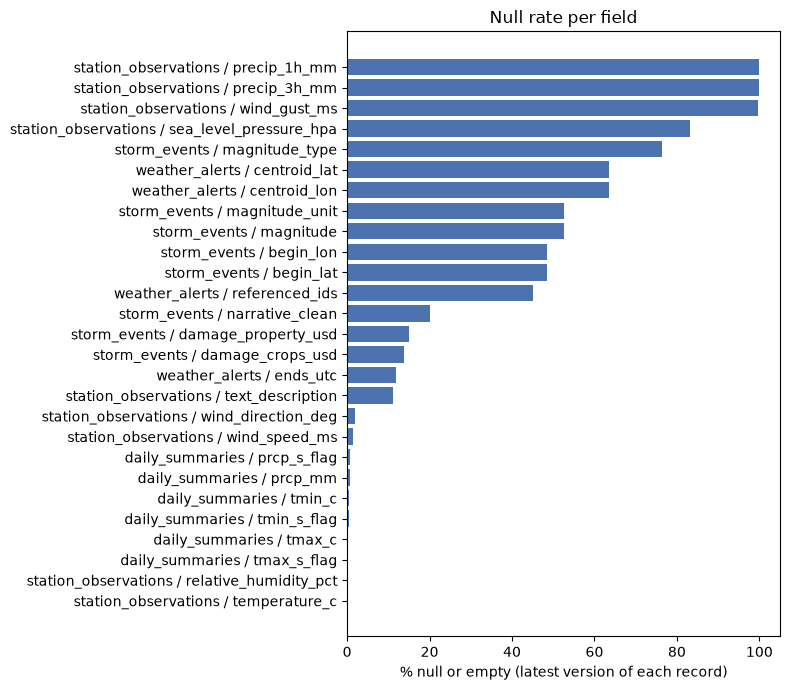

In [5]:
nulls = gov[(gov.section == "null_rate") & (gov.value > 0)].sort_values("value")
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(nulls.topic + " / " + nulls.dim_1, nulls.value, color="#4C72B0")
ax.set_xlabel("% null or empty (latest version of each record)")
ax.set_title("Null rate per field")
fig.tight_layout()

In [6]:
runs = gov[gov.section == "ingestion_compliance"].pivot_table(index=["topic", "period"], columns="metric",
                                                              values="value")
save_table(runs.reset_index(), "gold_governance_ingestion.png", "governance: ingestion_compliance")
runs

metric                           compliance_pct  runs_actual  runs_expected
topic                period                                                
station_observations 2026-11-17           20.83          5.0           24.0
                     2026-11-18            0.00          0.0           24.0
                     2026-11-19            8.33          2.0           24.0
                     2026-11-20           11.76          2.0           17.0
weather_alerts       2026-11-17           16.67          4.0           24.0
                     2026-11-18            0.00          0.0           24.0
                     2026-11-19            8.33          2.0           24.0
                     2026-11-20           11.76          2.0           17.0

dim_1,KAUS,KDFW,KIAH
period,,,
2022-01-01,100.00,100.00,100.00
2023-01-01,100.00,100.00,100.00
2024-01-01,100.00,100.00,100.00
2025-01-01,100.00,100.00,100.00
2026-01-01,97.84,97.84,97.84


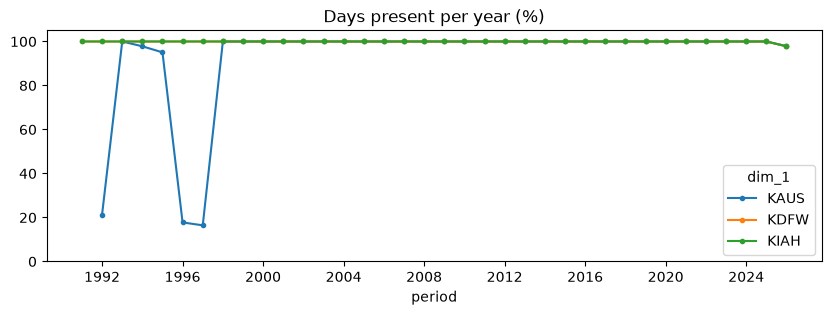

In [7]:
complete = gov[(gov.section == "station_completeness") & (gov.metric == "days_present_pct")] \
    .pivot_table(index="period", columns="dim_1", values="value")
ax = complete.plot(figsize=(10, 3), marker=".", title="Days present per year (%)")
ax.set_ylim(0, 105)
complete.tail()

## 2. Storytelling summary

**Narrative.** How unusual is the weather at our Texas stations compared with their own 1991-2020 history,
when does the National Weather Service warn about it, and do our EXTREME days match real storm impacts?
The functional user should leave knowing (1) whether today is normal at each station, (2) that recent days are
skewed to the warm side of the baseline, and (3) that EXTREME days carry more storm reports than normal days.

In [8]:
days = story[(story.section == "station_day_class") & (story.metric == "observed")]
save_table(story[story.section == "station_day_class"].sort_values(["period", "dim_1", "dim_2", "metric"]).tail(12)[cols],
           "gold_storytelling_station_day.png", f"{storytelling_file.name}: station_day_class (last rows)")
mix = days.groupby(["dim_2", "label"]).size().unstack(fill_value=0)
(100 * mix.div(mix.sum(axis=1), axis=0)).round(1)

label,EXTREME_HIGH,EXTREME_LOW,NORMAL,UNUSUAL_HIGH,UNUSUAL_LOW
dim_2,,,,,
PRCP,0.9,0.0,90.9,8.3,0.0
TMAX,2.1,1.1,75.4,15.4,5.9
TMIN,2.1,0.9,79.7,13.2,4.0


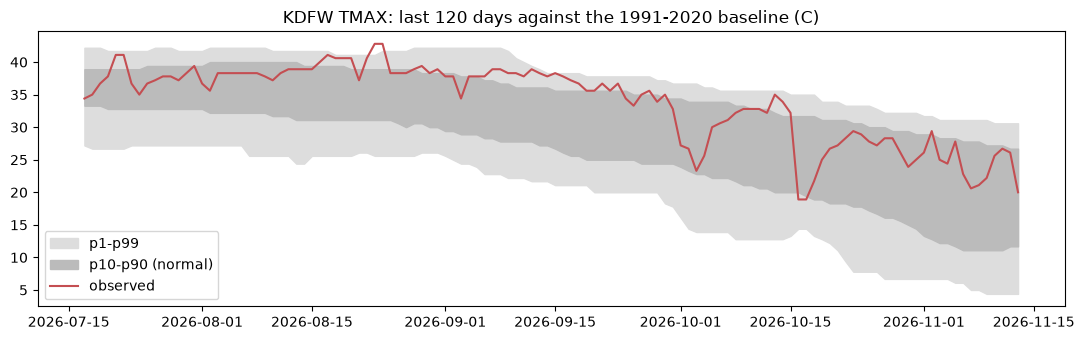

In [9]:
station, element = "KDFW", "TMAX"
band = story[(story.section == "station_day_class") & (story.dim_1 == station) & (story.dim_2 == element)] \
    .pivot_table(index="period", columns="metric", values="value").sort_index().tail(120)
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.fill_between(band.index, band.p01, band.p99, color="#DDDDDD", label="p1-p99")
ax.fill_between(band.index, band.p10, band.p90, color="#BBBBBB", label="p10-p90 (normal)")
ax.plot(band.index, band.observed, color="#C44E52", label="observed")
ax.set_title(f"{station} {element}: last 120 days against the 1991-2020 baseline (C)")
ax.legend(loc="lower left")
fig.tight_layout()
fig.savefig(EVIDENCE / "story_band.png", dpi=110)

In [10]:
current = story[story.section == "current_situation"].pivot_table(index="dim_1", columns="metric", values="value")
alerts_now = story[(story.section == "current_situation") & (story.metric == "active_alerts")][["dim_1", "label"]]
situation = story[story.section == "current_situation"]
save_table(situation[(situation.dim_1 == "KDFW") | (situation.metric == "active_alerts")][cols],
           "gold_storytelling_current.png", "storytelling: current_situation (KDFW and active alerts)")
current.join(alerts_now.set_index("dim_1"))

,active_alerts,dewpoint_c,latitude,longitude,pressure_hpa,relative_humidity_pct,temperature_c,wind_speed_ms,label
dim_1,,,,,,,,,
KAUS,0.0,13.0,30.19,-97.67,1021.6734,77.310000,17.0,0.00,
KDFW,0.0,13.0,32.90,-97.03,1022.0121,77.310000,17.0,2.06,
KIAH,0.0,15.0,29.97,-95.35,1021.6734,72.938767,20.0,2.06,


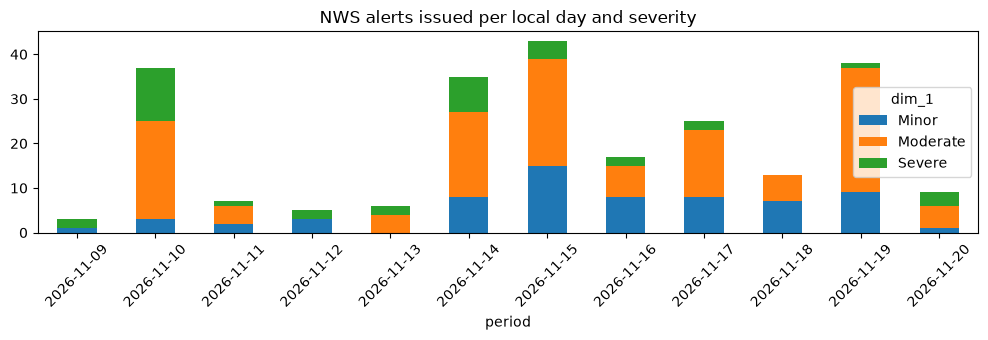

In [11]:
severity = story[(story.section == "alert_severity_daily") & (story.dim_1 != "ALL")] \
    .pivot_table(index="period", columns="dim_1", values="value", fill_value=0)
ax = severity.plot.bar(stacked=True, figsize=(10, 3.5), title="NWS alerts issued per local day and severity")
ax.set_xticklabels([str(p) for p in severity.index], rotation=45)
plt.tight_layout()

In [12]:
keywords = story[(story.section == "top_keywords") & (story.topic == "weather_alerts")]
association = story[story.section == "keyword_severity"].pivot_table(index="dim_1", columns="metric", values="value")
print(keywords[keywords.dim_2 == "bigram"][["dim_1", "value"]].head(10).to_string(index=False))
association.sort_values("mean_severity_score", ascending=False).head(10)

             dim_1  value
additional details   65.0
     beach erosion   71.0
     coastal flood  101.0
  coastal flooding   68.0
      current risk  100.0
         dense fog   68.0
driving conditions   63.0
    flood advisory  110.0
       flood stage   65.0
          high rip  100.0


metric,alerts,mean_severity_score
dim_1,,
morning,77.0,2.220779
county,70.0,2.171429
near,72.0,2.152778
texas,86.0,2.139535
mile,77.0,2.064935
hazardous,66.0,2.060606
driving,63.0,2.000000
feet,65.0,2.000000
dense,65.0,2.000000


In [13]:
impact = story[story.section == "storm_impact_by_type"].pivot_table(index="dim_1", columns="metric", values="value")
impact.sort_values("damage_usd", ascending=False).head(10)

metric,damage_usd,deaths,events,injuries
dim_1,,,,
Hail,3.080881e+09,0.0,6918.0,11.0
Flash Flood,1.325155e+09,158.0,1976.0,4.0
Flood,5.176082e+08,5.0,261.0,2.0
Frost/Freeze,4.601576e+08,1.0,256.0,0.0
Wildfire,3.276105e+08,3.0,256.0,6.0
Drought,2.301700e+08,0.0,4706.0,0.0
Thunderstorm Wind,2.281545e+08,16.0,4968.0,77.0
Extreme Cold/Wind Chill,1.500798e+08,30.0,246.0,0.0
Tornado,1.309080e+08,21.0,619.0,423.0


In [14]:
hits = story[story.section == "extreme_vs_storms"].pivot_table(index=["dim_1", "dim_2"], columns="metric", values="value")
save_table(hits.reset_index(), "gold_storytelling_extreme_vs_storms.png", "storytelling: extreme_vs_storms")
hits.round(1)

metric         days_with_storm_report_pct  station_days
dim_1 dim_2                                            
ALL   EXTREME                        16.6         331.0
      NORMAL                          3.5        3284.0
      UNUSUAL                         9.7        1863.0
KAUS  EXTREME                        14.4         104.0
      NORMAL                          3.4        1091.0
      UNUSUAL                         7.8         631.0
KDFW  EXTREME                        24.5         110.0
      NORMAL                          4.4        1159.0
      UNUSUAL                        12.9         557.0
KIAH  EXTREME                        11.1         117.0
      NORMAL                          2.7        1034.0
      UNUSUAL                         8.9         675.0

In [15]:
story[story.section == "source_comparison"][["dim_1", "dim_2", "value", "label"]]

,dim_1,dim_2,value,label
3556,F2 GHCN-Daily,API,38018.0,1991-01-01 to 2026-11-13
3557,F4 NWS observations,API,1362.0,2026-11-16 to 2026-11-20
3558,F1 Storm Events,web scraping,29051.0,2021-01-01 to 2025-12-31
3559,F3 NWS alerts,API,264.0,2026-11-10 to 2026-11-20
